In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
rotten_df =  pd.read_csv("../../../data/processed/rotten_tomatoes_cleaned.csv")


In [9]:
rotten_df.columns

Index(['title', 'genre', 'director', 'original_language', 'summary',
       'critic_reviews_count', 'critic_score_percentage',
       'audience_score_percentage', 'is_audience_rating_verified',
       'audience_rating_count', 'release_date_theaters_year',
       'release_date_theaters_month', 'release_date_theaters_day',
       'runtime_hour', 'runtime_minutes'],
      dtype='object')

### Explications des colonnes 

- **`title`** : titre du film.
- **`genre`** : genre cinématographique du film.
- **`director`** : nom du réalisateur du film.
- **`original_language`** : langue originale du film.
- **`summary`** : résumé de l'histoire du film.
- **`critic_reviews_count`** : nombre de critiques professionnelles prises en compte pour le film.
- **`critic_score_percentage`** : pourcentage d'avis positifs des critiques professionnels.
- **`audience_score_percentage`** : pourcentage d'avis positifs des spectateurs.
- **`is_audience_rating_verified`** : Indique si les notes du public sont vérifiées par Rotten Tomatoes en confirmant que les utilisateurs ont acheté des billets pour le film. 
- **`audience_rating_count`** : nombre total d'évaluations enregistrées auprès du public.
- **`release_date_theaters_year`** : année de sortie du film au cinéma.
- **`release_date_theaters_month`** : mois de sortie du film au cinéma.
- **`release_date_theaters_day`** : jour de sortie du film au cinéma.
- **`runtime_hour`** : nombre d'heures complètes que dure le film.
- **`runtime_minutes`** : nombre de minutes restantes après les heures complètes.

In [ ]:
print("number of films")
print(len(rotten_df))
print("number of null")
display(rotten_df.isna().sum())
print("number of duplicated")
print("dplicate rows==>", rotten_df.duplicated().sum())



number of films
3311
number of null


title                          0
genre                          0
director                       0
original_language              0
summary                        0
critic_reviews_count           0
critic_score_percentage        0
audience_score_percentage      0
is_audience_rating_verified    0
audience_rating_count          0
release_date_theaters_year     0
release_date_theaters_month    0
release_date_theaters_day      0
runtime_hour                   0
runtime_minutes                0
dtype: int64

number of duplicated
Duplicate rows: 0


In [17]:
rotten_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3311 entries, 0 to 3310
Data columns (total 15 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   title                        3311 non-null   object 
 1   genre                        3311 non-null   object 
 2   director                     3311 non-null   object 
 3   original_language            3311 non-null   object 
 4   summary                      3311 non-null   object 
 5   critic_reviews_count         3311 non-null   int64  
 6   critic_score_percentage      3311 non-null   float64
 7   audience_score_percentage    3311 non-null   float64
 8   is_audience_rating_verified  3311 non-null   bool   
 9   audience_rating_count        3311 non-null   int64  
 10  release_date_theaters_year   3311 non-null   int64  
 11  release_date_theaters_month  3311 non-null   int64  
 12  release_date_theaters_day    3311 non-null   int64  
 13  runtime_hour      

In [18]:
rotten_df.describe()

,critic_reviews_count,critic_score_percentage,audience_score_percentage,audience_rating_count,release_date_theaters_year,release_date_theaters_month,release_date_theaters_day,runtime_hour,runtime_minutes
count,3311.000000,3311.000000,3311.000000,3311.000000,3311.000000,3311.000000,3311.000000,3311.000000,3311.000000
mean,71.052250,67.270915,65.972516,13862.518876,2016.470553,6.597705,14.911205,1.150408,34.382362
std,82.995901,26.844624,21.080600,45568.626987,12.432280,3.458609,8.823203,0.386751,13.999373
min,5.000000,0.000000,0.000000,50.000000,1922.000000,1.000000,1.000000,0.000000,0.000000
25%,14.000000,49.000000,51.000000,50.000000,2016.000000,4.000000,7.000000,1.000000,27.000000
50%,37.000000,75.000000,69.000000,250.000000,2020.000000,7.000000,15.000000,1.000000,35.000000
75%,96.000000,90.000000,83.000000,2500.000000,2023.000000,10.000000,22.000000,1.000000,45.000000
max,581.000000,100.000000,100.000000,250000.000000,2026.000000,12.000000,31.000000,4.000000,59.000000


### Etude de corrélation entre les valeurs numérique

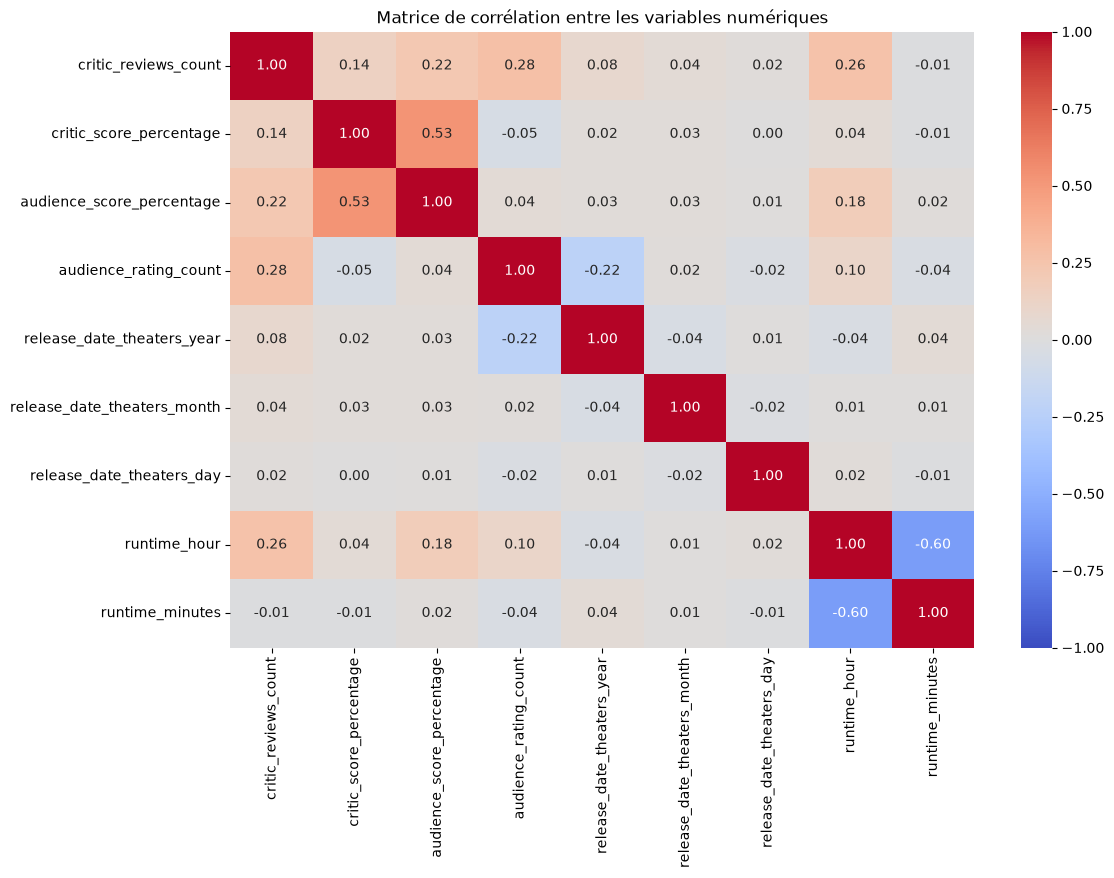

In [11]:
numerical_df = rotten_df.select_dtypes(include="number")

# Calculer la matrice de corrélation
correlation_matrix = numerical_df.corr()
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Matrice de corrélation entre les variables numériques")
plt.show()

- `critic_score_percentage` ↔ `audience_score_percentage` : +0.53  
  Interprétation : les films appréciés par le public ont généralement tendance à être également appréciés par les critiques professionnels.

- `critic_reviews_count` ↔ `audience_rating_count` : +0.28  
  Interprétation : les films qui reçoivent davantage de critiques professionnelles tendent également à recevoir davantage d'évaluations du public.

- `critic_reviews_count` ↔ `runtime_hour` : +0.26  
  Interprétation : les films les plus longs tendent à recevoir davantage de critiques professionnelles.

- `critic_reviews_count` ↔ `audience_score_percentage` : +0.22  
  Interprétation : les films ayant un score plus élevé auprès du public tendent légèrement à recevoir davantage de critiques professionnelles.

- `audience_score_percentage` ↔ `runtime_hour` : +0.18  
  Interprétation : les films les plus longs tendent légèrement à obtenir de meilleurs scores auprès du public.

- `critic_reviews_count` ↔ `critic_score_percentage` : +0.14  
  Interprétation : les films qui reçoivent davantage de critiques professionnelles tendent légèrement à obtenir un meilleur score auprès des critiques.

- `audience_rating_count` ↔ `runtime_hour` : +0.10  
  Interprétation : les films les plus longs tendent légèrement à recevoir davantage d'évaluations du public.

- `critic_reviews_count` ↔ `release_date_theaters_year` : +0.08  
  Interprétation : le nombre de critiques professionnelles présente une très faible tendance à augmenter avec l'année de sortie des films.

## Quelle est la période durant laquelle les films sont le plus fréquemment publiés, et quelle est l’évolution du nombre de films par an ?

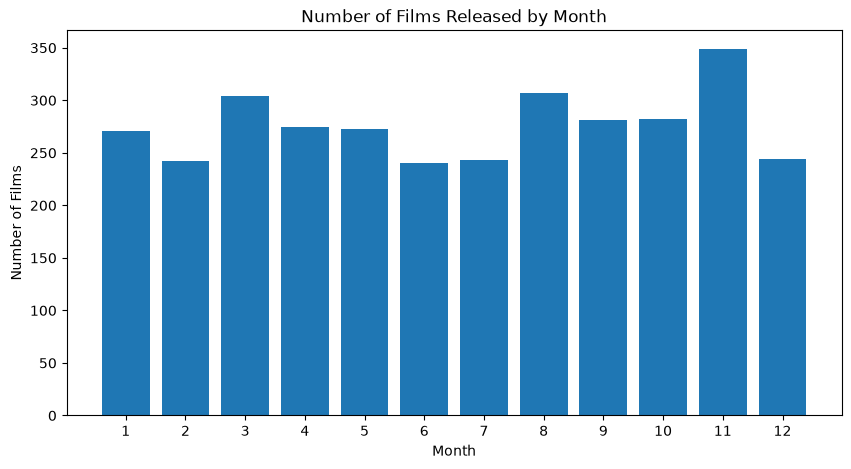

In [35]:
# 1. Films released by month
month_counts = rotten_df["release_date_theaters_month"].value_counts().sort_index()

plt.figure(figsize=(10, 5))
plt.bar(month_counts.index, month_counts.values)
plt.title("Number of Films Released by Month")
plt.xlabel("Month")
plt.ylabel("Number of Films")
plt.xticks(range(1, 13))
plt.show()

##### On remarque une certaine stabilité, avec une légère hausse au mois de novembre. On constate donc que les films sont publiés tout au long de l’année, avec une fréquence légèrement plus élevée en novembre.

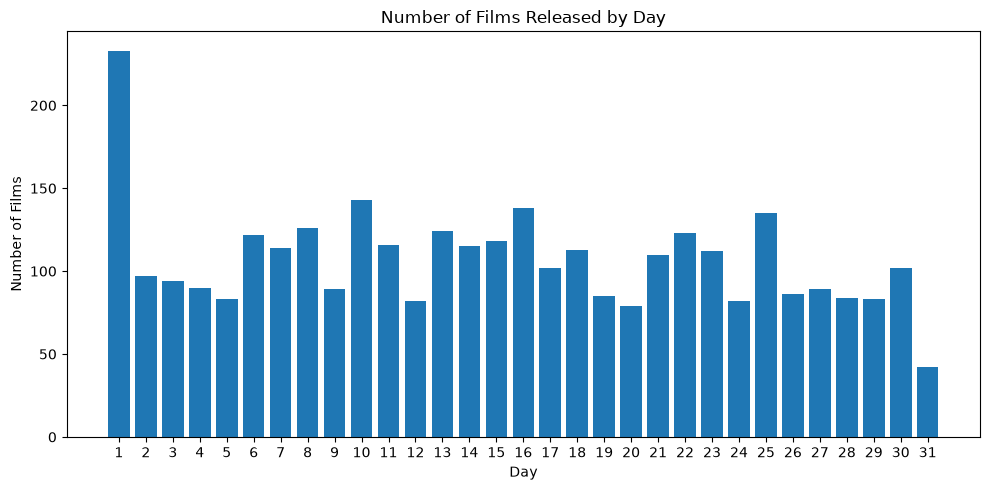

In [36]:
# 2. Films released by day
day_counts = rotten_df["release_date_theaters_day"].value_counts().sort_index()

plt.figure(figsize=(10, 5))
plt.bar(day_counts.index, day_counts.values)
plt.title("Number of Films Released by Day")
plt.xlabel("Day")
plt.ylabel("Number of Films")
plt.xticks(range(1, 32))
plt.tight_layout()
plt.show()

##### On remarque que des films sont publiés chaque jour du mois, avec une fréquence plus élevée le premier jour et plus faible le 31.

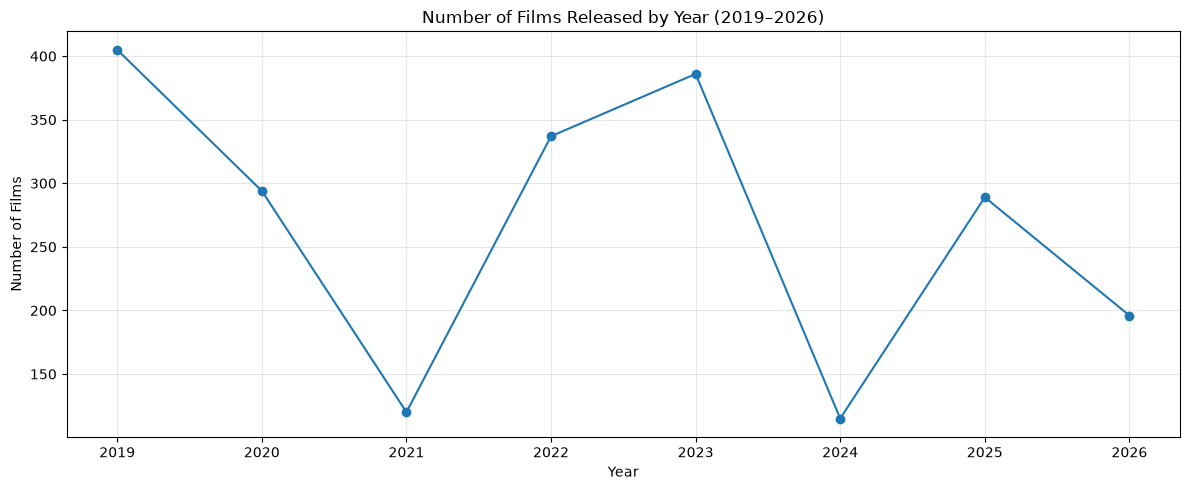

In [45]:

year_counts = (
    rotten_df.loc[
        rotten_df["release_date_theaters_year"].between(2019, 2026),
        "release_date_theaters_year"
    ]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(12, 5))
plt.plot(year_counts.index, year_counts.values, marker="o")
plt.title("Number of Films Released by Year (2019–2026)")
plt.xlabel("Year")
plt.ylabel("Number of Films")
plt.xticks(range(2019, 2027))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

##### On peut expliquer la diminution du nombre de films publiés entre 2019 et 2021 par la pandémie de COVID-19. 

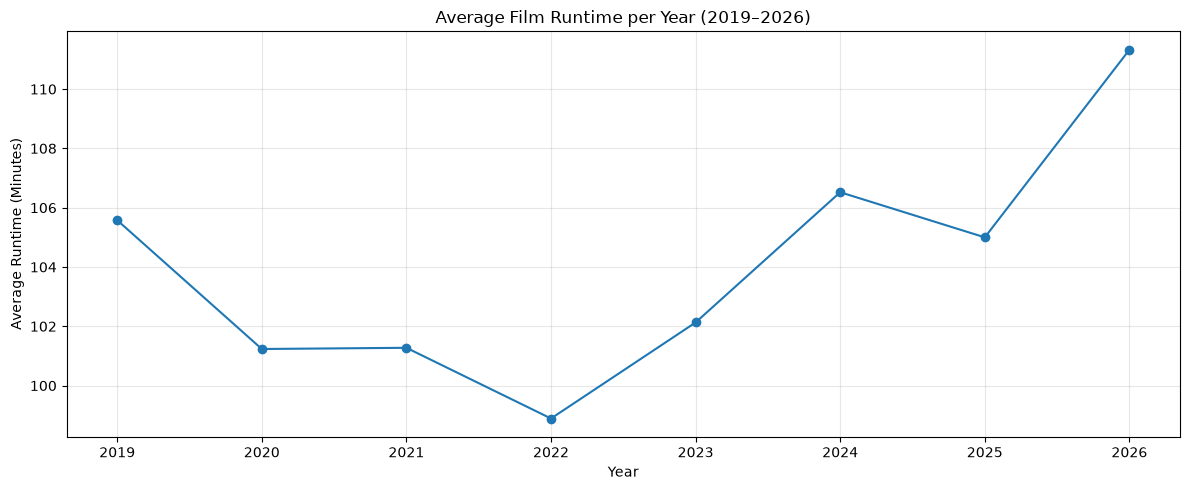

In [52]:
rotten_df["runtime_total_minutes"] = (
    rotten_df["runtime_hour"] * 60
    + rotten_df["runtime_minutes"]
)

# Filter years from 2019 to 2026
recent_movies = rotten_df[
    rotten_df["release_date_theaters_year"].between(2019, 2026)
]

# Calculate average runtime per year
average_runtime_year = (
    recent_movies.groupby("release_date_theaters_year")["runtime_total_minutes"]
    .mean()
    .reset_index()
)

# Plot the line graph
plt.figure(figsize=(12, 5))
plt.plot(
    average_runtime_year["release_date_theaters_year"],
    average_runtime_year["runtime_total_minutes"],
    marker="o"
)

plt.title("Average Film Runtime per Year (2019–2026)")
plt.xlabel("Year")
plt.ylabel("Average Runtime (Minutes)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

##### On remarque une diminution de la durée moyenne des films entre 2019 et 2022, suivie d’une augmentation entre 2022 et 2026. Cette évolution est quelque peu inattendue, car la consommation de contenus courts, tels que les Reels, est devenue de plus en plus populaire. On pourrait donc s’attendre à ce que l’industrie cinématographique réduise la durée des films afin de mieux capter l’attention du public. Cependant, ce graphique montre une tendance inverse, avec une augmentation de la durée moyenne des films sur cette période. Cette tendance rejoint les observations d’un article publié par The Hollywood Reporter en 2026, qui souligne que les films à large diffusion deviennent plus longs. 
##### lien de l'article : https://www.hollywoodreporter.com/movies/movie-news/movies-getting-longer-1236555200/

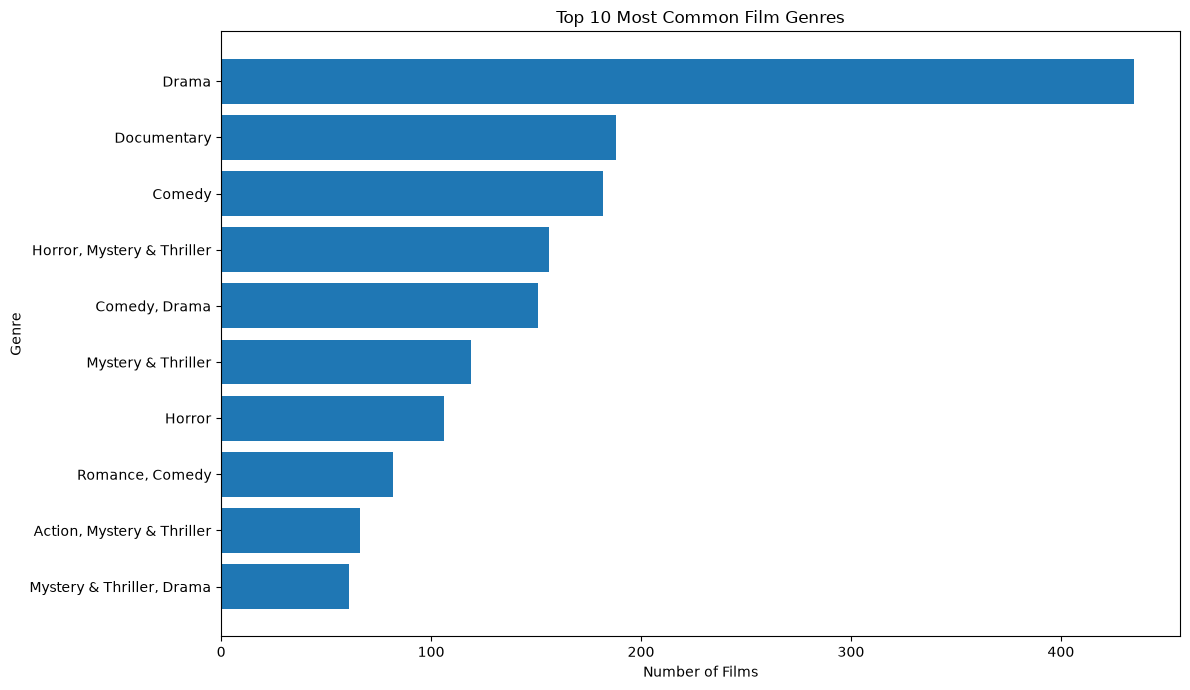

In [55]:

# Get the top 10 genres
genre_counts = rotten_df["genre"].value_counts().head(10).sort_values()

# Plot horizontal bar chart
plt.figure(figsize=(12, 7))
plt.barh(genre_counts.index, genre_counts.values)

plt.title("Top 10 Most Common Film Genres")
plt.xlabel("Number of Films")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

##### On constate que le drame (Drama) est le genre le plus représenté dans notre jeu de données. Cette observation rejoint celle de l’article de Stephen Follows cité ci-dessous, qui explique que le drame est l’un des genres les moins coûteux à produire, car il ne nécessite pas forcément de décors, de costumes ou d’effets spéciaux particuliers.

##### Lien de l’article : https://stephenfollows.com/p/genre-trends-global-film-production

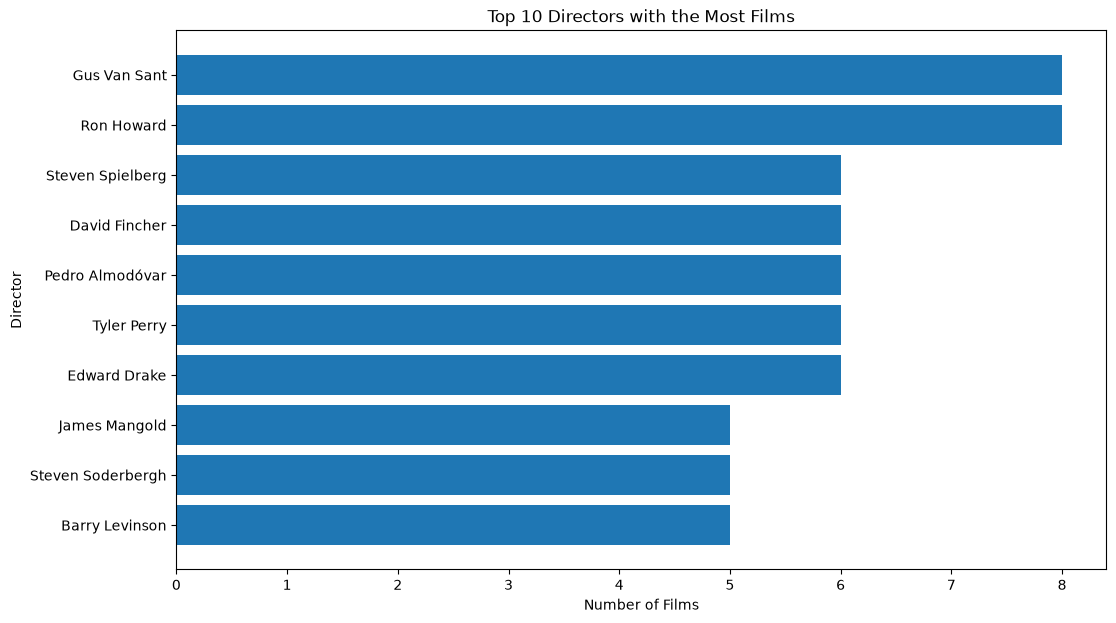

In [59]:
director_counts = rotten_df["director"].value_counts().head(10).sort_values()

plt.figure(figsize=(12, 7))
plt.barh(director_counts.index, director_counts.values)

plt.title("Top 10 Directors with the Most Films")
plt.xlabel("Number of Films")
plt.ylabel("Director")
plt.show()

In [63]:
language_counts = (
    rotten_df["original_language"]
    .value_counts()
    .head(10)
    .reset_index()
)

language_counts.columns = ["Language", "Number of Films"]

language_counts

,Language,Number of Films
0,English,2616
1,British English,104
2,French (France),68
3,Hindi,56
4,Spanish,55
5,Japanese,47
6,Chinese,42
7,Korean,36
8,German,27
9,Italian,26


In [95]:

# 1. PUBLIC : les 10 films avec le plus d'avis
audience_most_reviews = (
    rotten_df
    .nlargest(10, "audience_rating_count")
    [["title", "release_date_theaters_year",
      "audience_rating_count", "audience_score_percentage"]]
    .reset_index(drop=True)
)

print("TOP 10 — Films les plus évalués par le public ")
display(audience_most_reviews)


# 2. PUBLIC : les 10 films les mieux notés
audience_best_scores = (
    rotten_df[rotten_df["audience_rating_count"] > 25000]
    .nlargest(10, "audience_score_percentage")
    [["title", "release_date_theaters_year",
      "audience_score_percentage", "audience_rating_count"]]
    .reset_index(drop=True)
)

print("TOP 10 — Films les mieux notés par le public (+25 000 avis)")
display(audience_best_scores)


# 3. CRITIQUES : les 10 films avec le plus d'avis
critics_most_reviews = (
    rotten_df
    .nlargest(10, "critic_reviews_count")
    [["title", "release_date_theaters_year",
      "critic_reviews_count", "critic_score_percentage"]]
    .reset_index(drop=True)
)

print("TOP 10 — Films les plus évalués par les critiques professionnels ")
display(critics_most_reviews)


# 4. CRITIQUES : les 10 films les mieux notés
critics_best_scores = (
    rotten_df[rotten_df["critic_reviews_count"] > 500]
    .nlargest(10, "critic_score_percentage")
    [["title", "release_date_theaters_year",
      "critic_score_percentage", "critic_reviews_count"]]
    .reset_index(drop=True)
)

print("TOP 10 — Films les mieux notés par les critiques professionnels (+500 critiques)")
display(critics_best_scores)


TOP 10 — Films les plus évalués par le public 


,title,release_date_theaters_year,audience_rating_count,audience_score_percentage
0,The Lion King,1994,250000,93.0
1,Charlie's Angels,2000,250000,45.0
2,The Grudge,2004,250000,46.0
3,Lady and the Tramp,1955,250000,80.0
4,Child's Play,1988,250000,66.0
5,Hellboy,2004,250000,66.0
6,Dumbo,1941,250000,70.0
7,Serenity,2005,250000,91.0
8,War,2007,250000,51.0
9,Just Friends,2005,250000,71.0


TOP 10 — Films les mieux notés par le public (+25 000 avis)


,title,release_date_theaters_year,audience_score_percentage,audience_rating_count
0,The Godfather,2013,98.0,250000
1,Seven,1995,95.0,250000
2,Seven,2025,95.0,250000
3,Seven,2010,95.0,250000
4,The Professional,2013,95.0,250000
5,Rear Window,1954,95.0,100000
6,Psycho,1960,95.0,100000
7,Toy Story 4,2019,94.0,50000
8,Aladdin,2019,94.0,50000
9,Alien,2014,94.0,250000


TOP 10 — Films les plus évalués par les critiques professionnels 


,title,release_date_theaters_year,critic_reviews_count,critic_score_percentage
0,Once Upon a Time... In Hollywood,2019,581,86.0
1,Avengers: Endgame,2019,552,94.0
2,Captain Marvel,2019,545,79.0
3,Star Wars: The Rise of Skywalker,2019,522,51.0
4,Barbie,2023,508,88.0
5,Killers of the Flower Moon,2023,475,93.0
6,Knives Out,2019,472,97.0
7,The Irishman,2019,467,95.0
8,Toy Story 4,2019,461,96.0
9,Wonder Woman 1984,2020,455,57.0


TOP 10 — Films les mieux notés par les critiques professionnels (+500 critiques)


,title,release_date_theaters_year,critic_score_percentage,critic_reviews_count
0,Avengers: Endgame,2019,94.0,552
1,Barbie,2023,88.0,508
2,Once Upon a Time... In Hollywood,2019,86.0,581
3,Captain Marvel,2019,79.0,545
4,Star Wars: The Rise of Skywalker,2019,51.0,522
